Figure 3: Focused drug screen across NF1 patients reveals heterogeneous morphology responses to small molecules.
Panel A: Workflow of drug screen - https://github.com/MikeLippincott/NF1_organoid_profile_analysis/blob/cb382f79362e54511216839385894911ef528c39/figures/drugs_figure/figures/cell_structures_targets.png 
Panel B: Single-cell counts per well FOV by tumor type - 1.EDA/figures/cell_counts/single_cell_biology.pdf (page 2)
Panel C: Heatmap of features at Aggregated data level - https://github.com/MikeLippincott/NF1_organoid_profile_analysis/blob/8570d312b4186fab54fbb99b08c8e04dc32e3cfc/1.EDA/figures/profile_heatmaps/3D_sc_consensus_profile_heatmaps.pdf (page 79 of pdf)
Panel D: Image montage of select examples - figures/assembled_figure_x/media/Whole_montage.png

Dropped: the former segmentation-category heatmap and differential-feature-analysis panels are no longer part of this figure. Remaining panels are tagged A/B/C/D on assembly.

## Note on sources
Panel A is read directly from `figures/drugs_figure/figures/` (merged via PR #78).

Panel C is sourced from a branch/PR that has not merged to `main` yet, so its file is staged under `../data/source_panels/` rather than read from its eventual in-repo location:
- Panel C: page 79 (the all-patients clustered heatmap) of `3D_sc_consensus_profile_heatmaps.pdf`, from this repo at commit `8570d31` (PR-pending)

Once the upstream PR merges, repoint the path above at the merged location and delete the staging directory. (The old staged `cell_structures_targets.png` is no longer read now that panel A is merged, and can be deleted. The former panels B and D have been dropped, so their staged sources - `confusion_heatmap_Logistic_Regression.png` and `morphology_vs_viability_cosine_similarity.pdf` - are no longer read either.)

Panel E is read directly from `../media/Whole_montage.png` (already in this module, not staged).

Layout is `A / C / E` stacked as three full-width rows (re-tagged A/B/C), saved as a single PNG.

In [1]:
list_of_packages <- c("ggplot2", "dplyr", "patchwork", "magick", "grid", "RColorBrewer")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(package, character.only = TRUE, quietly = TRUE, warn.conflicts = FALSE)
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

root_dir <- find_git_root()
source(file.path(root_dir, "utils", "r_plot_themes.r"))
source(file.path(root_dir, "utils", "r_plot_funcs.r"))

module_dir <- file.path(root_dir, "figures", "assembled_figure_3")
source_panels_dir <- file.path(module_dir, "data", "source_panels")
media_dir <- file.path(module_dir, "media")
figures_dir <- file.path(module_dir, "figures")
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)

## Panel helpers
Embed a saved PNG or a single PDF page as a patchwork-compatible panel.

In [2]:
pad_image_to_aspect <- function(img, target_aspect, gravity = "center") {
    #' Pad a magick image with white to an exact width/height aspect ratio,
    #' keeping the original UNDISTORTED. Whitespace is added to whichever
    #' dimension is too short; `gravity` places the image within the padded
    #' box ("center", "west" = flush left, "east" = flush right, ...).
    #' Returns the image unchanged when `target_aspect` is NULL.
    if (is.null(target_aspect)) {
        return(img)
    }
    info <- magick::image_info(img)
    w <- info$width
    h <- info$height
    if (target_aspect > w / h) {
        new_w <- round(h * target_aspect)
        new_h <- h
    } else {
        new_w <- w
        new_h <- round(w / target_aspect)
    }
    magick::image_extent(
        img, geometry = paste0(new_w, "x", new_h),
        gravity = gravity, color = "white"
    )
}

embed_png_panel <- function(path, target_aspect = NULL, gravity = "center") {
    #' Reads a saved PNG, trims its (mostly white) border margin, and wraps
    #' it as a patchwork-compatible panel that exactly fills its grid cell
    #' (unit(1, "npc") width/height). Filling a cell only avoids distortion
    #' when the cell's aspect matches the image's, so pass `target_aspect`
    #' (the cell's width/height) to letterbox-pad the trimmed image to that
    #' aspect first: the plot then keeps its proportions and any leftover
    #' space in the cell becomes whitespace (placed per `gravity`) instead
    #' of stretch.
    if (!file.exists(path)) {
        stop(
            "missing ", path, " - run the notebook that saves this figure first."
        )
    }
    img <- pad_image_to_aspect(
        magick::image_trim(magick::image_read(path)), target_aspect, gravity
    )
    wrap_elements(
        full = grid::rasterGrob(
            as.raster(img), interpolate = TRUE,
            width = unit(1, "npc"), height = unit(1, "npc")
        )
    )
}

embed_pdf_page_panel <- function(path, page, target_aspect = NULL, gravity = "center") {
    #' Same as embed_png_panel(), but rasterizes a single page of a PDF
    #' first. Uses the `pdftoppm` CLI (poppler-utils) rather than
    #' magick::image_read_pdf(), which additionally requires the R
    #' `pdftools` package.
    if (!file.exists(path)) {
        stop(
            "missing ", path, " - run the notebook that saves this figure first."
        )
    }
    png_root <- tempfile()
    status <- system2(
        "pdftoppm",
        c("-f", page, "-l", page, "-r", "600", "-png", "-singlefile", path, png_root)
    )
    if (status != 0) stop("pdftoppm failed with status ", status)
    on.exit(unlink(paste0(png_root, ".png")), add = TRUE)
    img <- pad_image_to_aspect(
        magick::image_trim(magick::image_read(paste0(png_root, ".png"))),
        target_aspect, gravity
    )
    wrap_elements(
        full = grid::rasterGrob(
            as.raster(img), interpolate = TRUE,
            width = unit(1, "npc"), height = unit(1, "npc")
        )
    )
}

## Build panels A-D

In [3]:
# Trimmed aspect ratios (width/height) of each panel's own image.
aspect_a <- 5884 / 4946  # drug_targets_on_ras_mapk_pi3k_pathway.png (trimmed)
aspect_counts <- 4665 / 3509  # single_cell_biology.pdf, page 2 (counts by tumor type, trimmed)
aspect_c <- 3227 / 1480  # 3D_sc_consensus_profile_heatmaps.pdf, page 79 (trimmed)
aspect_umap_patient <- 3215 / 1547  # umap_image_frame.pdf, page 3 (Patient, closest points; trimmed)

# 2x2 grid, filled row-major (tags A/B/C/D follow position):
#   A pathway         | B heatmap
#   C cell counts     | D UMAP (patient, closest)
# Unequal columns: a NARROW left column holds the two squarer panels (A pathway,
# C counts) and a WIDE right column holds the two wide panels (B heatmap,
# D UMAP). A and C both fill the left column, so they render at the same width;
# B and D both fill the wide right column, so they expand to the full remaining
# width. No panel is stretched - each is letterbox-padded with white to its
# cell's aspect, so leftover space becomes whitespace. Each row's height is set
# so its right-column panel fills the column width exactly (zero whitespace on
# B and D); the shorter left panels then sit in that height with a little
# vertical whitespace.
fig_width <- 20
# Left column width = the shared rendered width of A and C. Must stay small
# enough that A still fills it at the top row's height (<= ~7.06 for these
# aspects), otherwise A would gain side whitespace and read narrower than C.
left_col_width <- 7.0
right_col_width <- fig_width - left_col_width

# Row heights derived so the wide right-column panels fill their width exactly.
row_top_height <- right_col_width / aspect_c              # B heatmap fills width
row_bottom_height <- right_col_width / aspect_umap_patient  # D UMAP fills width

# Per-cell aspects (column width / row height) each panel is padded to.
a_cell_aspect <- left_col_width / row_top_height
b_cell_aspect <- right_col_width / row_top_height
c_cell_aspect <- left_col_width / row_bottom_height
d_cell_aspect <- right_col_width / row_bottom_height

# Top row.
panel_a <- embed_png_panel(
    file.path(root_dir, "figures/drugs_figure/figures/drug_targets_on_ras_mapk_pi3k_pathway.png"),
    target_aspect = a_cell_aspect, gravity = "west"
)
panel_c <- embed_pdf_page_panel(
    file.path(source_panels_dir, "3D_sc_consensus_profile_heatmaps.pdf"),
    page = 79, target_aspect = b_cell_aspect
)
# Bottom row.
panel_counts <- embed_pdf_page_panel(
    file.path(root_dir, "1.EDA", "figures", "cell_counts", "single_cell_biology.pdf"),
    page = 2, target_aspect = c_cell_aspect, gravity = "west"
)
# UMAP with example-image crops, patient coloring, closest (k-means) points:
# page 3 of the single multi-page PDF written by umap_image_frame.ipynb.
panel_umap_patient <- embed_pdf_page_panel(
    file.path(figures_dir, "umap_image_frame.pdf"),
    page = 3, target_aspect = d_cell_aspect
)

## Assemble
The four panels are arranged in a 2x2 grid with unequal columns, tagged
row-major A/B/C/D: pathway (A) and consensus heatmap (B) on top, cell counts
(C) and the UMAP image-frame montage (D, patient coloring, closest points) on
the bottom. A narrow left column holds the squarer panels A and C (which render
at the same width), and a wide right column holds B and D, which expand to fill
the remaining width. Nothing is stretched: each panel is letterbox-padded with
white to its cell's aspect, so spare space becomes whitespace. Row heights are
derived so B and D fill their column width exactly. Edit `left_col_width` to
re-balance the columns.

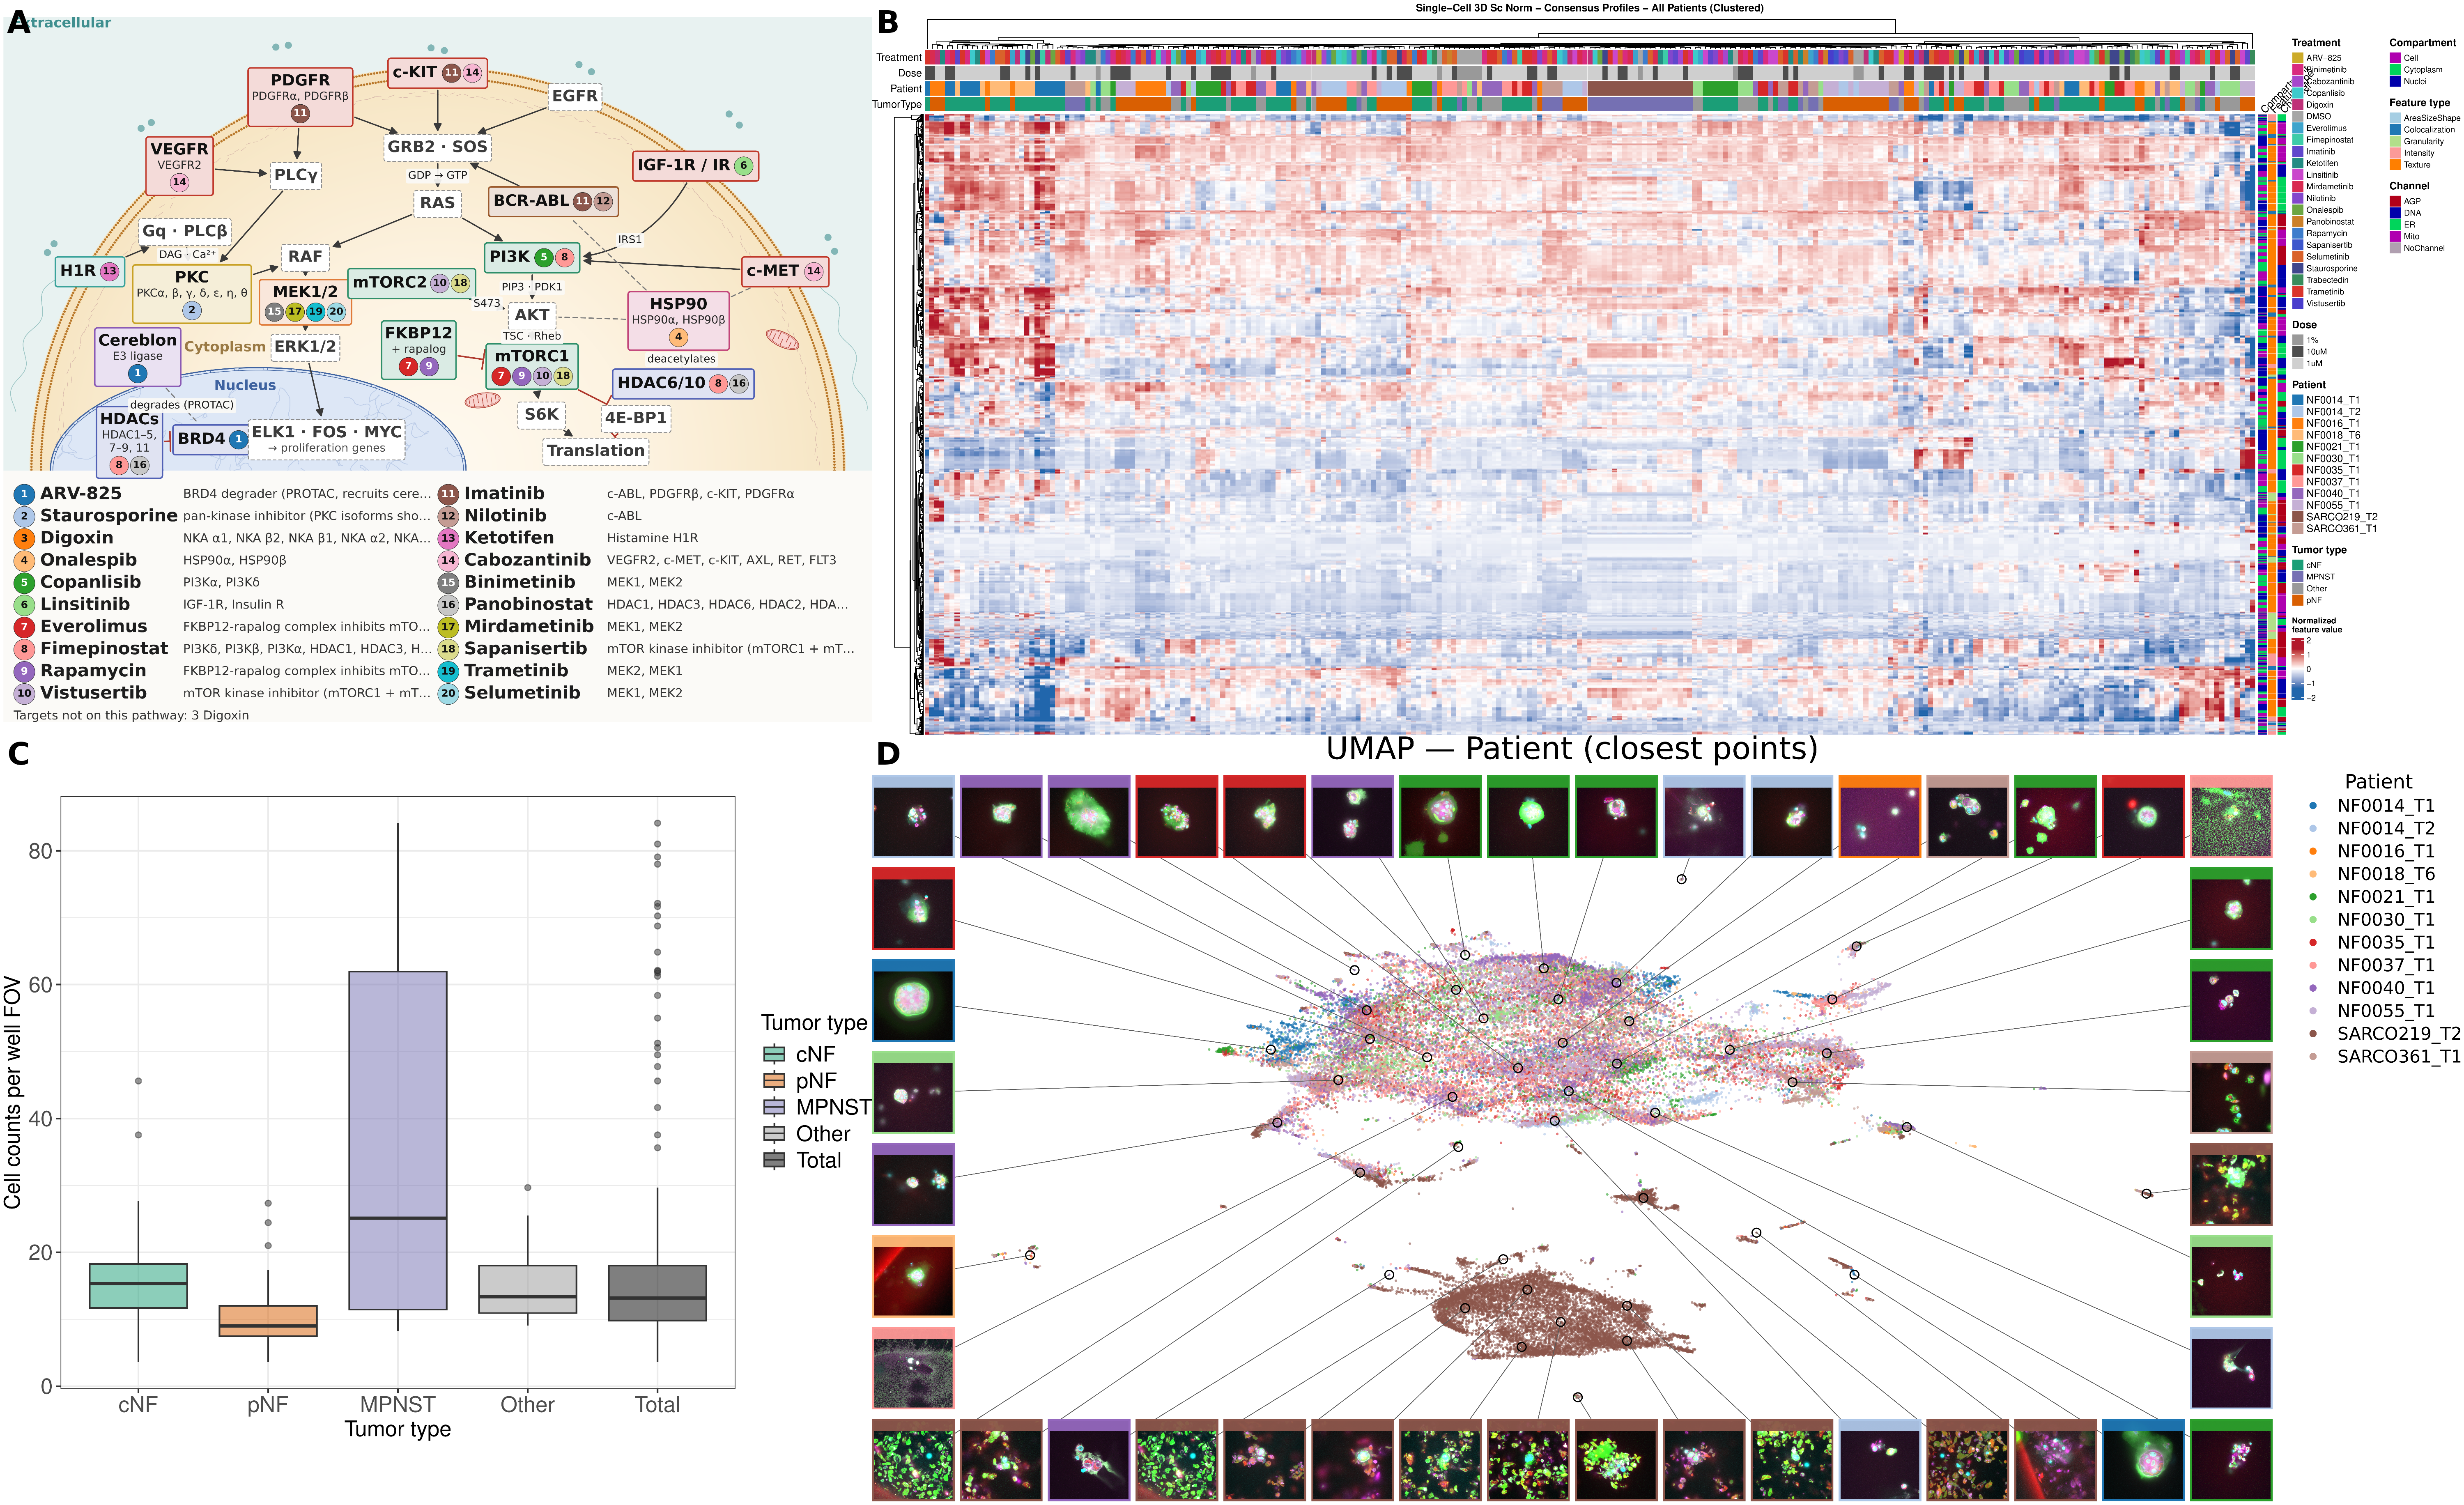

In [4]:
fig_height <- row_top_height + row_bottom_height
dims <- set_plot_size(fig_width, fig_height)

assembled_figure <- (
    wrap_plots(
        panel_a, panel_c, panel_counts, panel_umap_patient,
        ncol = 2, widths = c(left_col_width, right_col_width),
        heights = c(row_top_height, row_bottom_height)
    )
    + plot_annotation(tag_levels = "A")
    & theme(plot.margin = margin(2, 2, 2, 2), plot.tag = element_text(face = "bold", size = 18))
)

save_ggplot(
    assembled_figure,
    file.path(figures_dir, "assembled_figure_3.png"),
    width = dims$width, height = dims$height, dpi = 300, limitsize = FALSE
)